# Tech Challenge — Fase 2: demonstração

Otimização dos modelos de diagnóstico da Fase 1 com **algoritmo genético** e interpretação dos
resultados com **LLM**. Este notebook carrega os artefatos gerados por `main_ga.py`,
`main_ga_cnn.py` e `main_llm.py` e demonstra cada componente.

> Ferramenta de apoio à decisão — não substitui a avaliação médica.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
REPORTS, FIGS = ROOT / "outputs/reports", ROOT / "outputs/figures"

## 1. O algoritmo genético em miniatura

Cada indivíduo é um vetor de genes em [0, 1); cada gene é decodificado para um hiperparâmetro
(inteiro, real/log ou categórico). Abaixo, o cromossomo da Random Forest e a decodificação de um
indivíduo aleatório e da configuração original da Fase 1.

In [2]:
from src.ga.search_spaces import SEARCH_SPACES, BASELINE_PARAMS
space = SEARCH_SPACES["random_forest"]
rng = np.random.default_rng(0)
genome = space.random_genome(rng)
display(pd.DataFrame({"gene": space.names, "u (genoma)": genome.round(3),
                      "valor decodificado": list(space.decode(genome).values())}))
print("Fase 1 codificada:", space.encode(BASELINE_PARAMS["random_forest"]).round(3))

,gene,u (genoma),valor decodificado
0,n_estimators,0.637,273
1,max_depth,0.270,7
2,min_samples_leaf,0.041,1
3,max_features,0.017,sqrt
4,criterion,0.813,entropy
5,class_weight,0.913,balanced_subsample


Fase 1 codificada: [0.714 0.237 0.05  0.125 0.25  0.167]


Uma execução curta e ao vivo do GA na Decision Tree (3 gerações, população 10):

In [3]:
from src import data_loader, preprocessing, modeling
from src.ga.engine import GAConfig, GeneticAlgorithm
from src.ga.fitness import CVFitness

df, _ = preprocessing.clean_dataset(data_loader.load_dataset())
split = modeling.train_test_split_dataset(df)
fitness = CVFitness("decision_tree", split.X_train, split.y_train)
ga = GeneticAlgorithm(SEARCH_SPACES["decision_tree"], fitness, GAConfig(population_size=10, generations=3),
                      initial_params=[BASELINE_PARAMS["decision_tree"]], n_jobs=-1)
result = ga.run()
display(pd.DataFrame(result.history_records())[["generation", "best_fitness", "mean_fitness", "best_so_far", "unique_evaluations", "diversity"]].round(4))
print("Melhores hiperparâmetros:", result.best_params)

,generation,best_fitness,mean_fitness,best_so_far,unique_evaluations,diversity
0,0,0.9277,0.9113,0.9277,10,0.2799
1,1,0.9277,0.9170,0.9277,18,0.2158
2,2,0.9281,0.9209,0.9281,24,0.2436
3,3,0.9292,0.9216,0.9292,31,0.1867


Melhores hiperparâmetros: {'max_depth': 4, 'min_samples_split': 7, 'min_samples_leaf': 8, 'criterion': 'entropy', 'max_features': None, 'class_weight': 'balanced'}


## 2. Resultados dos experimentos (execução completa)

4 experimentos (cada um varia **um** fator em relação ao E1), 3 seeds cada, 15 gerações:

| Experimento | Configuração |
|---|---|
| E1_referencia | pop. 20, mutação 0.10, torneio k=3, crossover uniforme |
| E2_populacao_grande | pop. **40** |
| E3_mutacao_alta | mutação **0.30**, sigma 0.25 |
| E4_roleta_blend | seleção por **roleta** + crossover **BLX-α** |

In [4]:
summary = pd.read_csv(REPORTS / "ga_experiments_summary.csv")
summary[["model", "experiment", "best_fitness_mean", "best_fitness_std", "baseline_cv_fitness",
         "random_search_fitness", "evaluations_mean", "elapsed_seconds_mean"]].round(4)

,model,experiment,best_fitness_mean,best_fitness_std,baseline_cv_fitness,random_search_fitness,evaluations_mean,elapsed_seconds_mean
0,decision_tree,E1_referencia,0.9344,0.0050,0.8948,0.9325,131.3333,7.2770
1,decision_tree,E2_populacao_grande,0.9373,0.0024,0.8948,0.9325,299.6667,11.8469
2,decision_tree,E3_mutacao_alta,0.9310,0.0035,0.8948,0.9325,227.3333,9.0125
3,decision_tree,E4_roleta_blend,0.9310,0.0045,0.8948,0.9325,228.0000,8.9202
4,knn,E1_referencia,0.9630,0.0000,0.9551,0.9601,43.0000,5.2788
5,knn,E2_populacao_grande,0.9630,0.0000,0.9551,0.9601,69.0000,5.4124
6,knn,E3_mutacao_alta,0.9624,0.0010,0.9551,0.9601,55.6667,5.8709
7,knn,E4_roleta_blend,0.9624,0.0010,0.9551,0.9601,58.6667,5.6385
8,logistic_regression,E1_referencia,0.9768,0.0000,0.9666,0.9763,96.6667,31.0348
9,logistic_regression,E2_populacao_grande,0.9768,0.0000,0.9666,0.9763,213.3333,45.9754


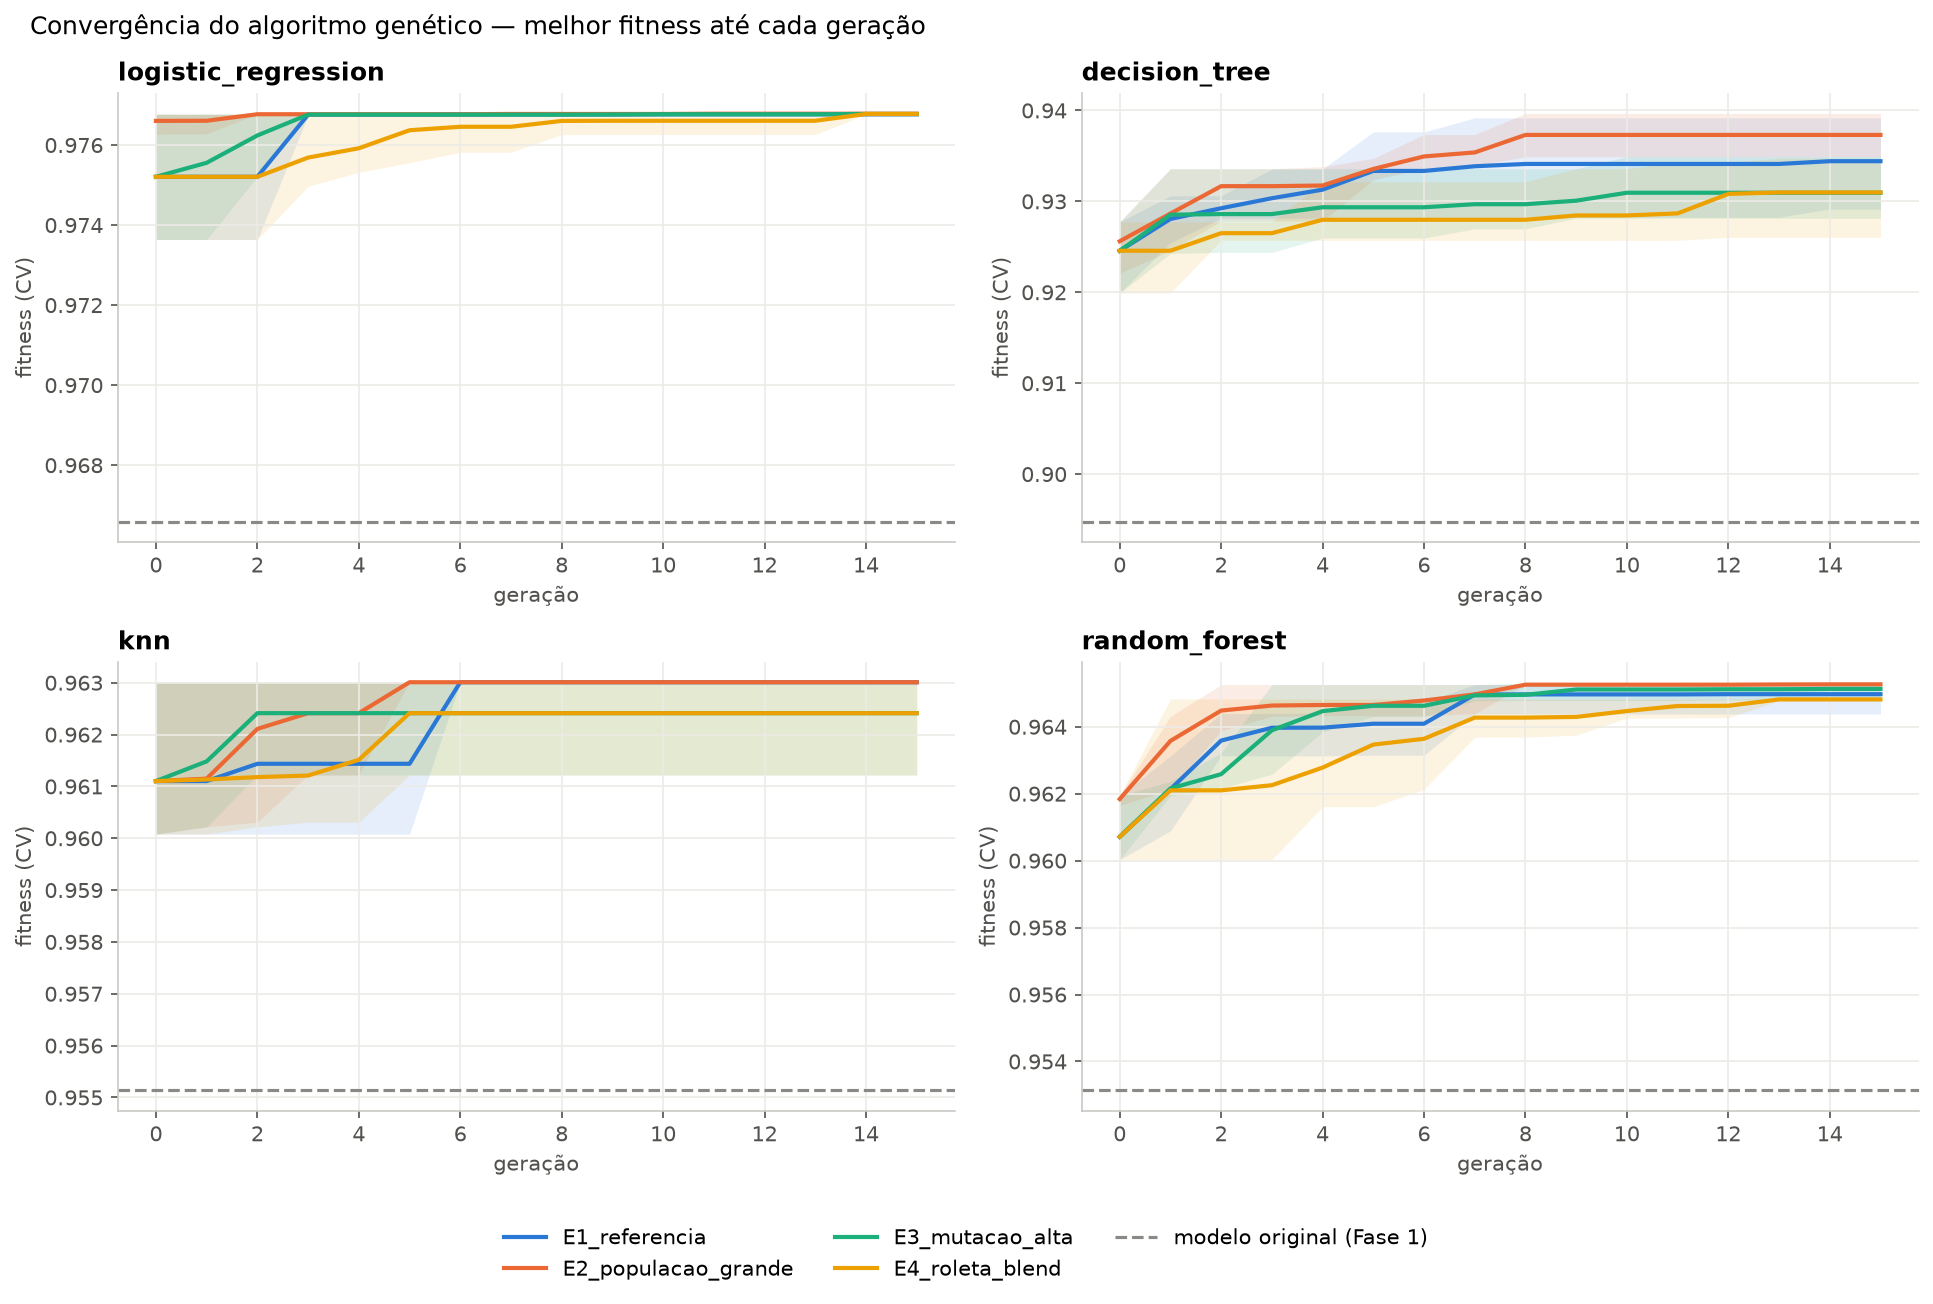

In [5]:
display(Image(FIGS / "ga_01_convergence.png"))

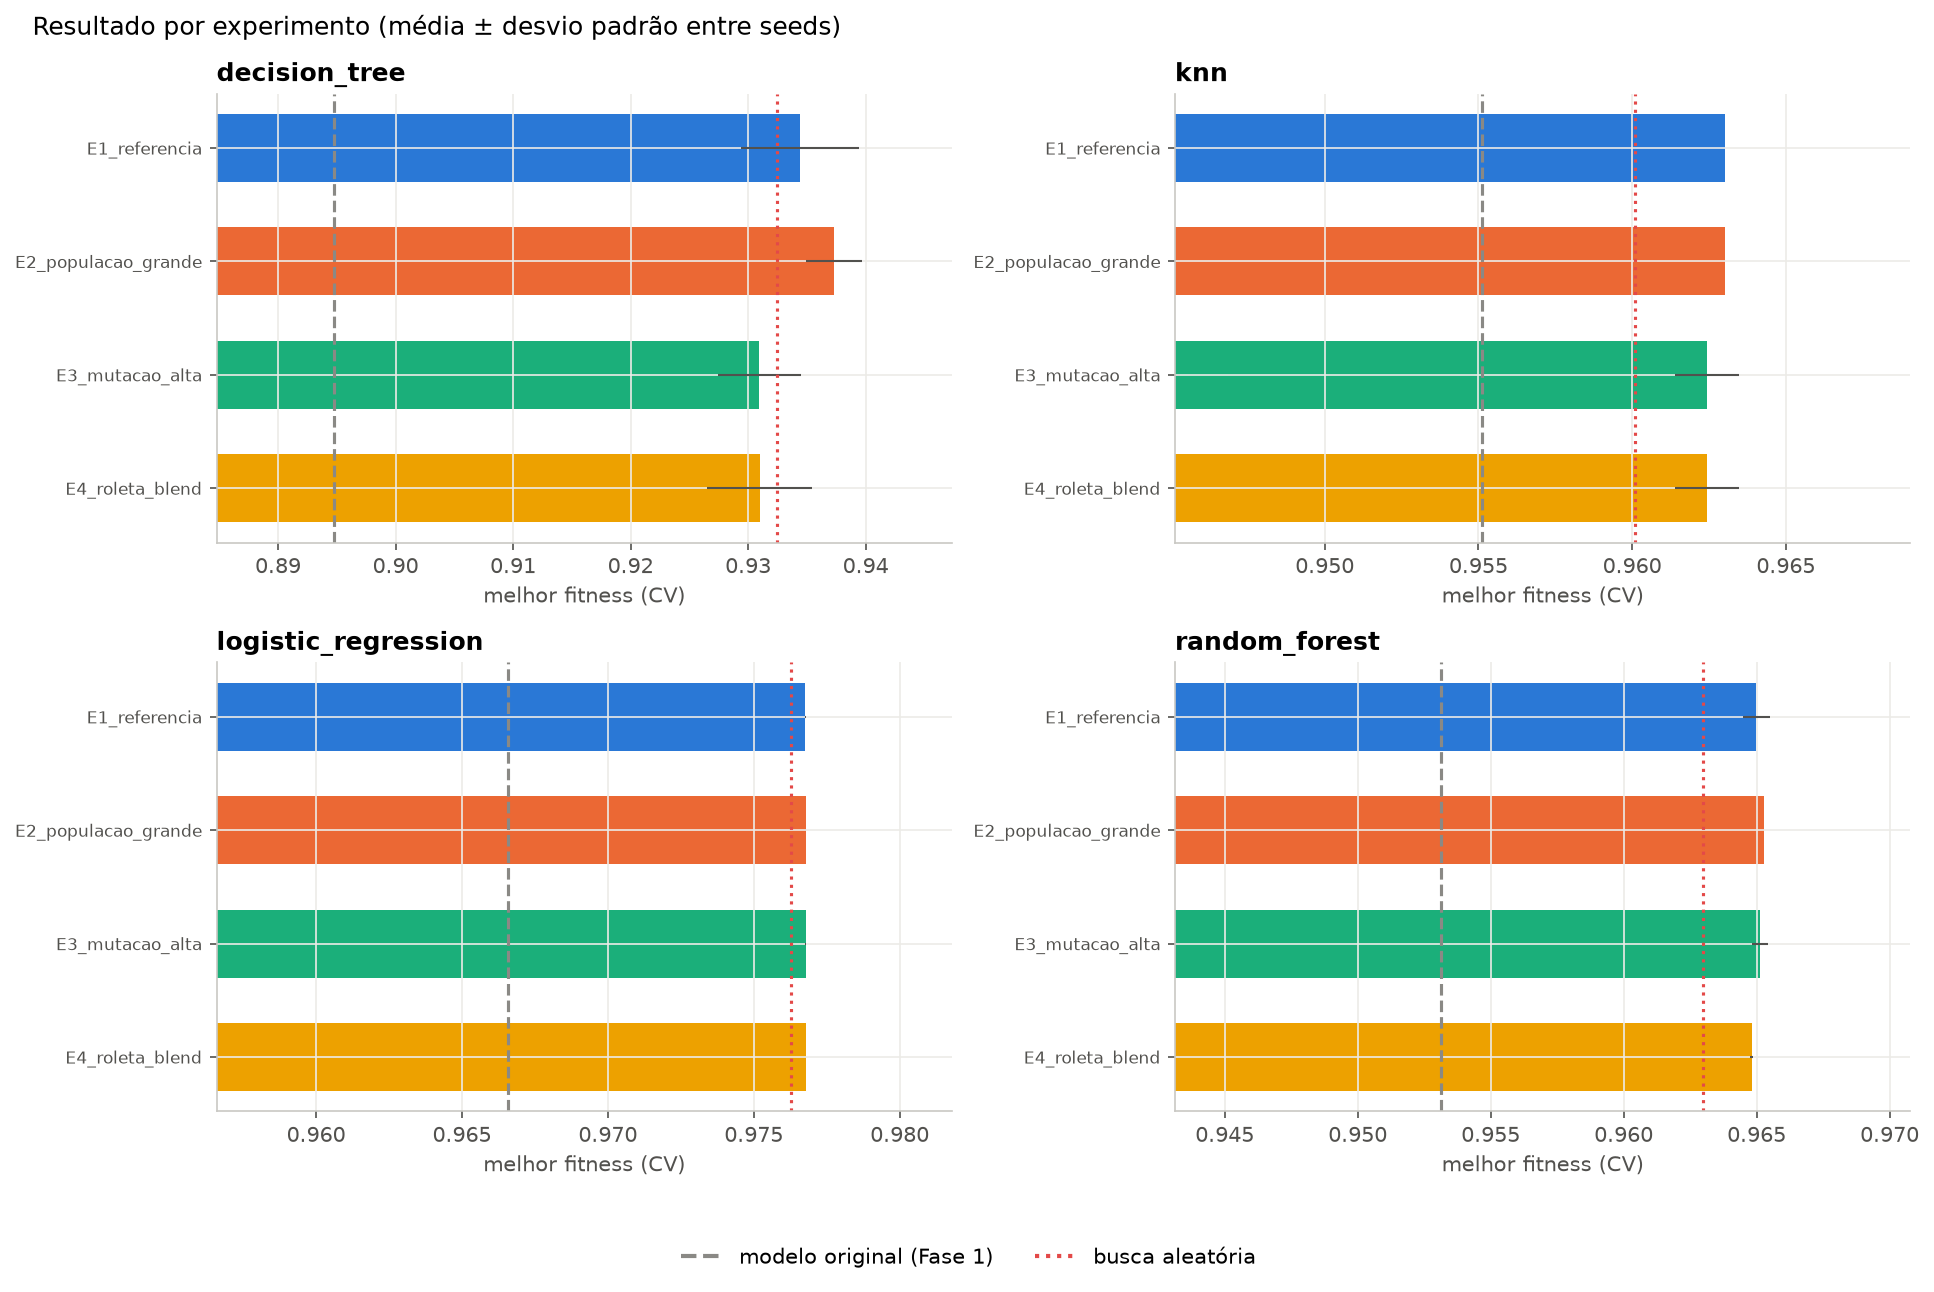

In [6]:
display(Image(FIGS / "ga_05_experiments_summary.png"))

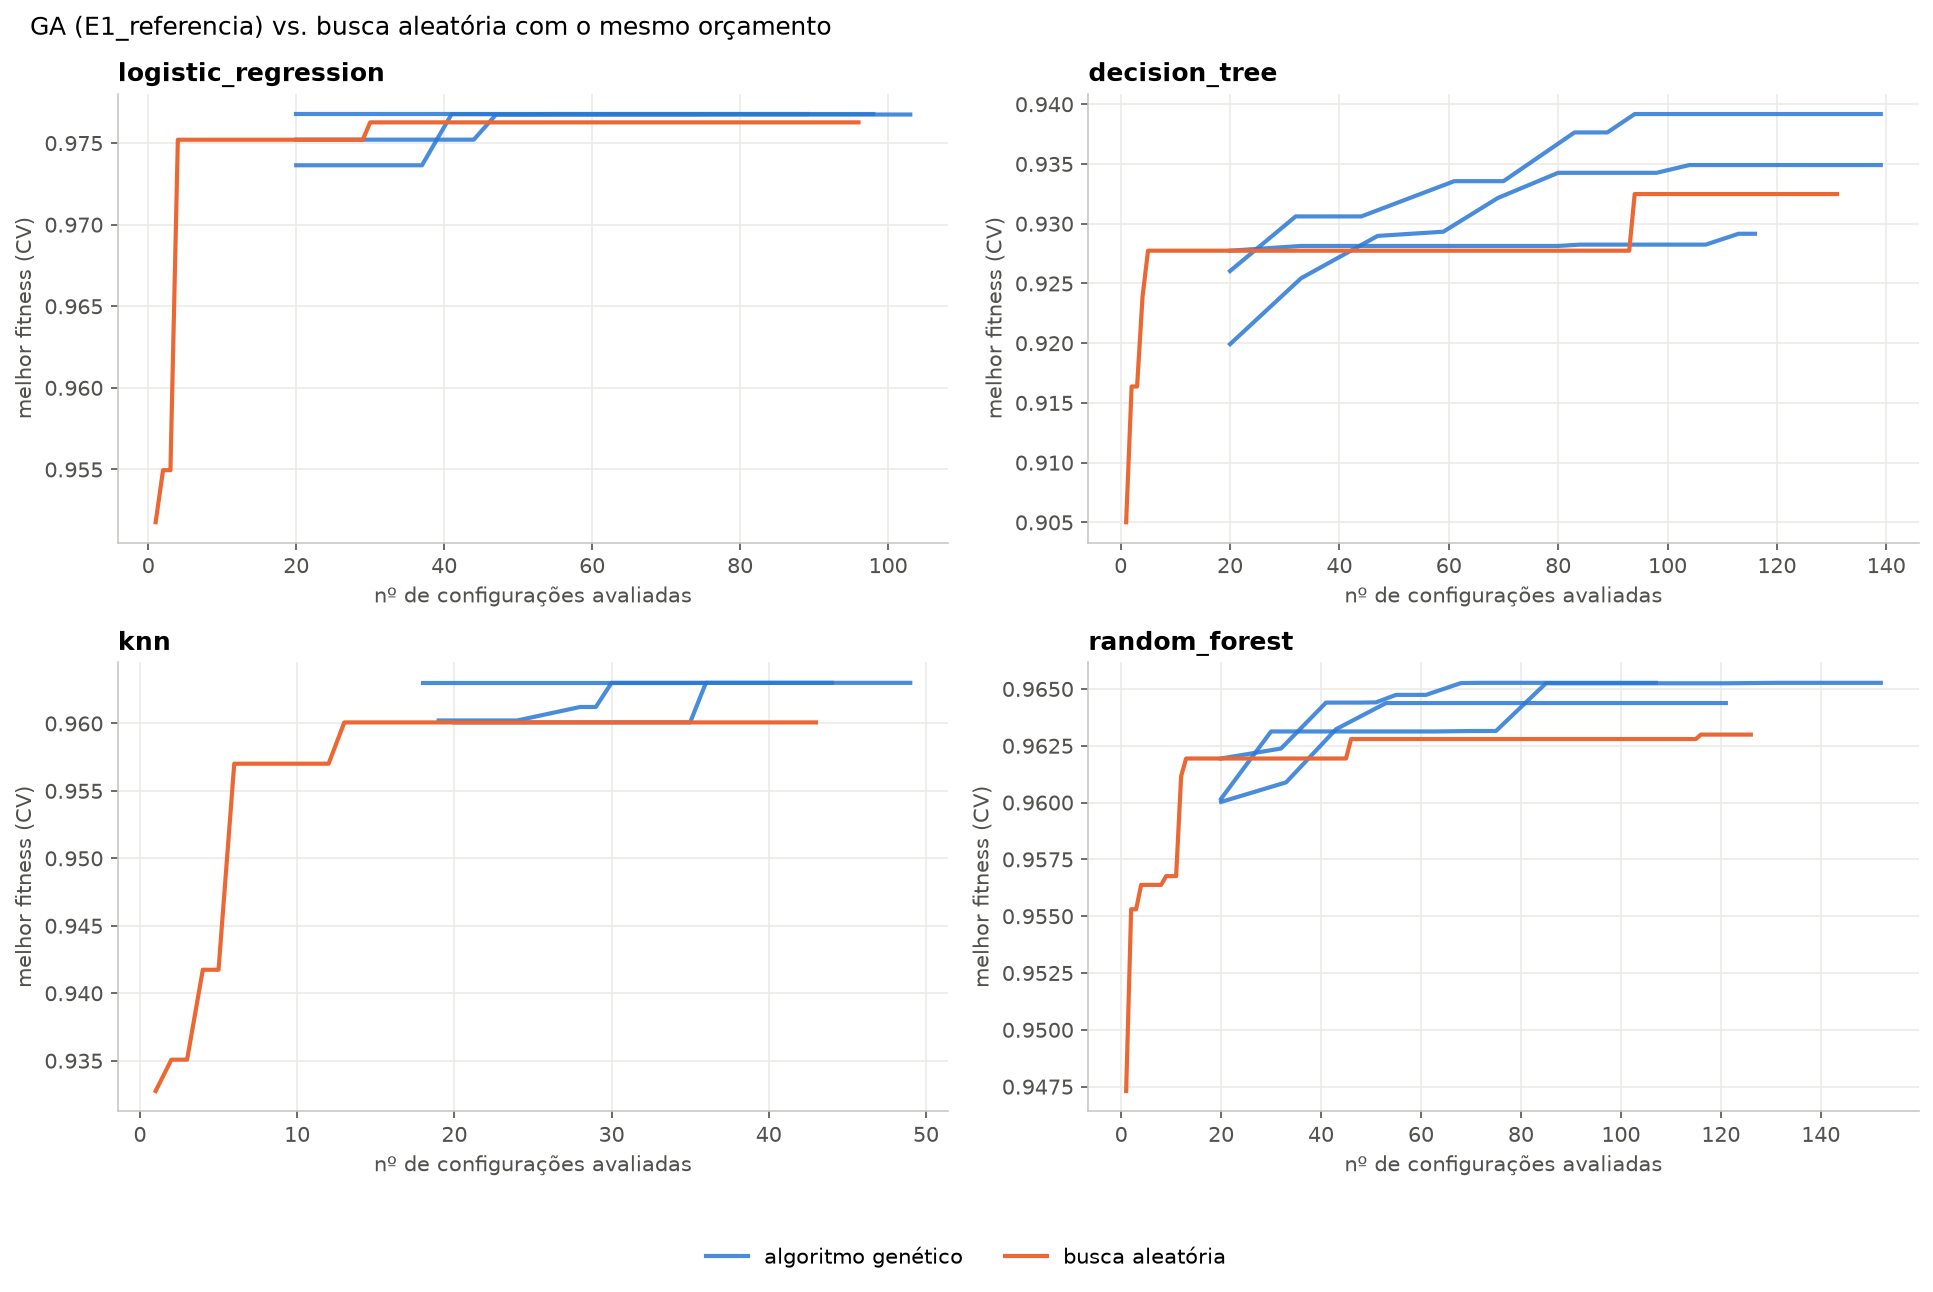

In [7]:
display(Image(FIGS / "ga_03_ga_vs_random_search.png"))

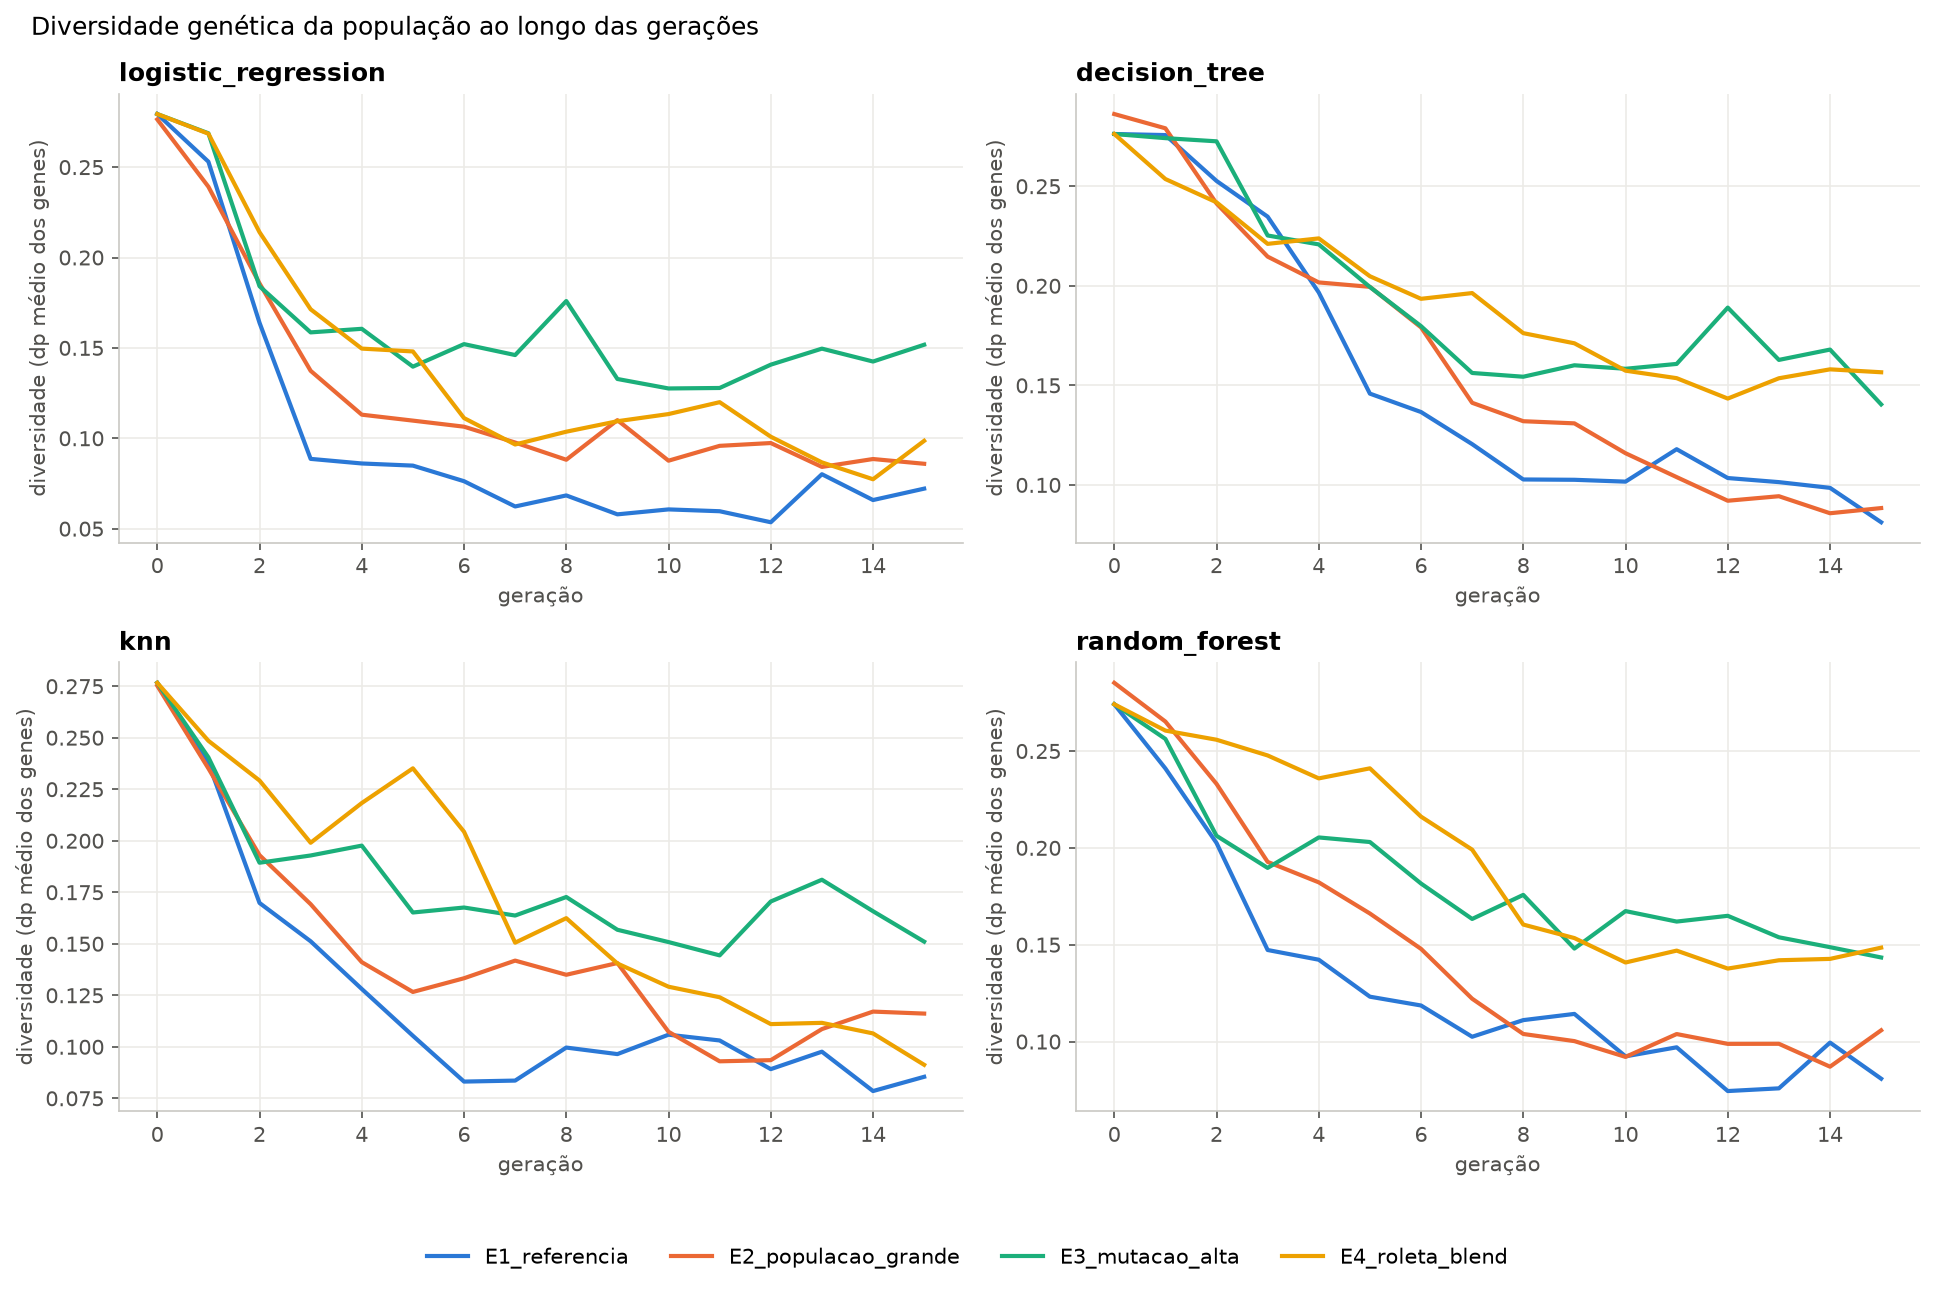

In [8]:
display(Image(FIGS / "ga_06_diversity.png"))

## 3. Original (Fase 1) vs. otimizado — conjunto de teste

In [9]:
comp = pd.read_csv(REPORTS / "comparison_original_vs_optimized.csv")
comp[[c for c in comp.columns if "_ci_" not in c]].round(4)

,model,version,cv_fitness,test_accuracy,test_precision_malignant,test_recall_malignant,test_f1_malignant,test_roc_auc
0,logistic_regression,original,0.9666,0.9825,0.9762,0.9762,0.9762,0.9954
1,logistic_regression,otimizado_ga,0.9768,0.9561,0.9111,0.9762,0.9425,0.9957
2,decision_tree,original,0.8948,0.9211,0.8667,0.9286,0.8966,0.9163
3,decision_tree,otimizado_ga,0.9397,0.9035,0.8444,0.9048,0.8736,0.9327
4,knn,original,0.9551,0.9737,1.0000,0.9286,0.9630,0.9884
5,knn,otimizado_ga,0.9630,0.9561,0.9512,0.9286,0.9398,0.9807
6,random_forest,original,0.9531,0.9474,0.9286,0.9286,0.9286,0.9937
7,random_forest,otimizado_ga,0.9653,0.9386,0.9070,0.9286,0.9176,0.9940


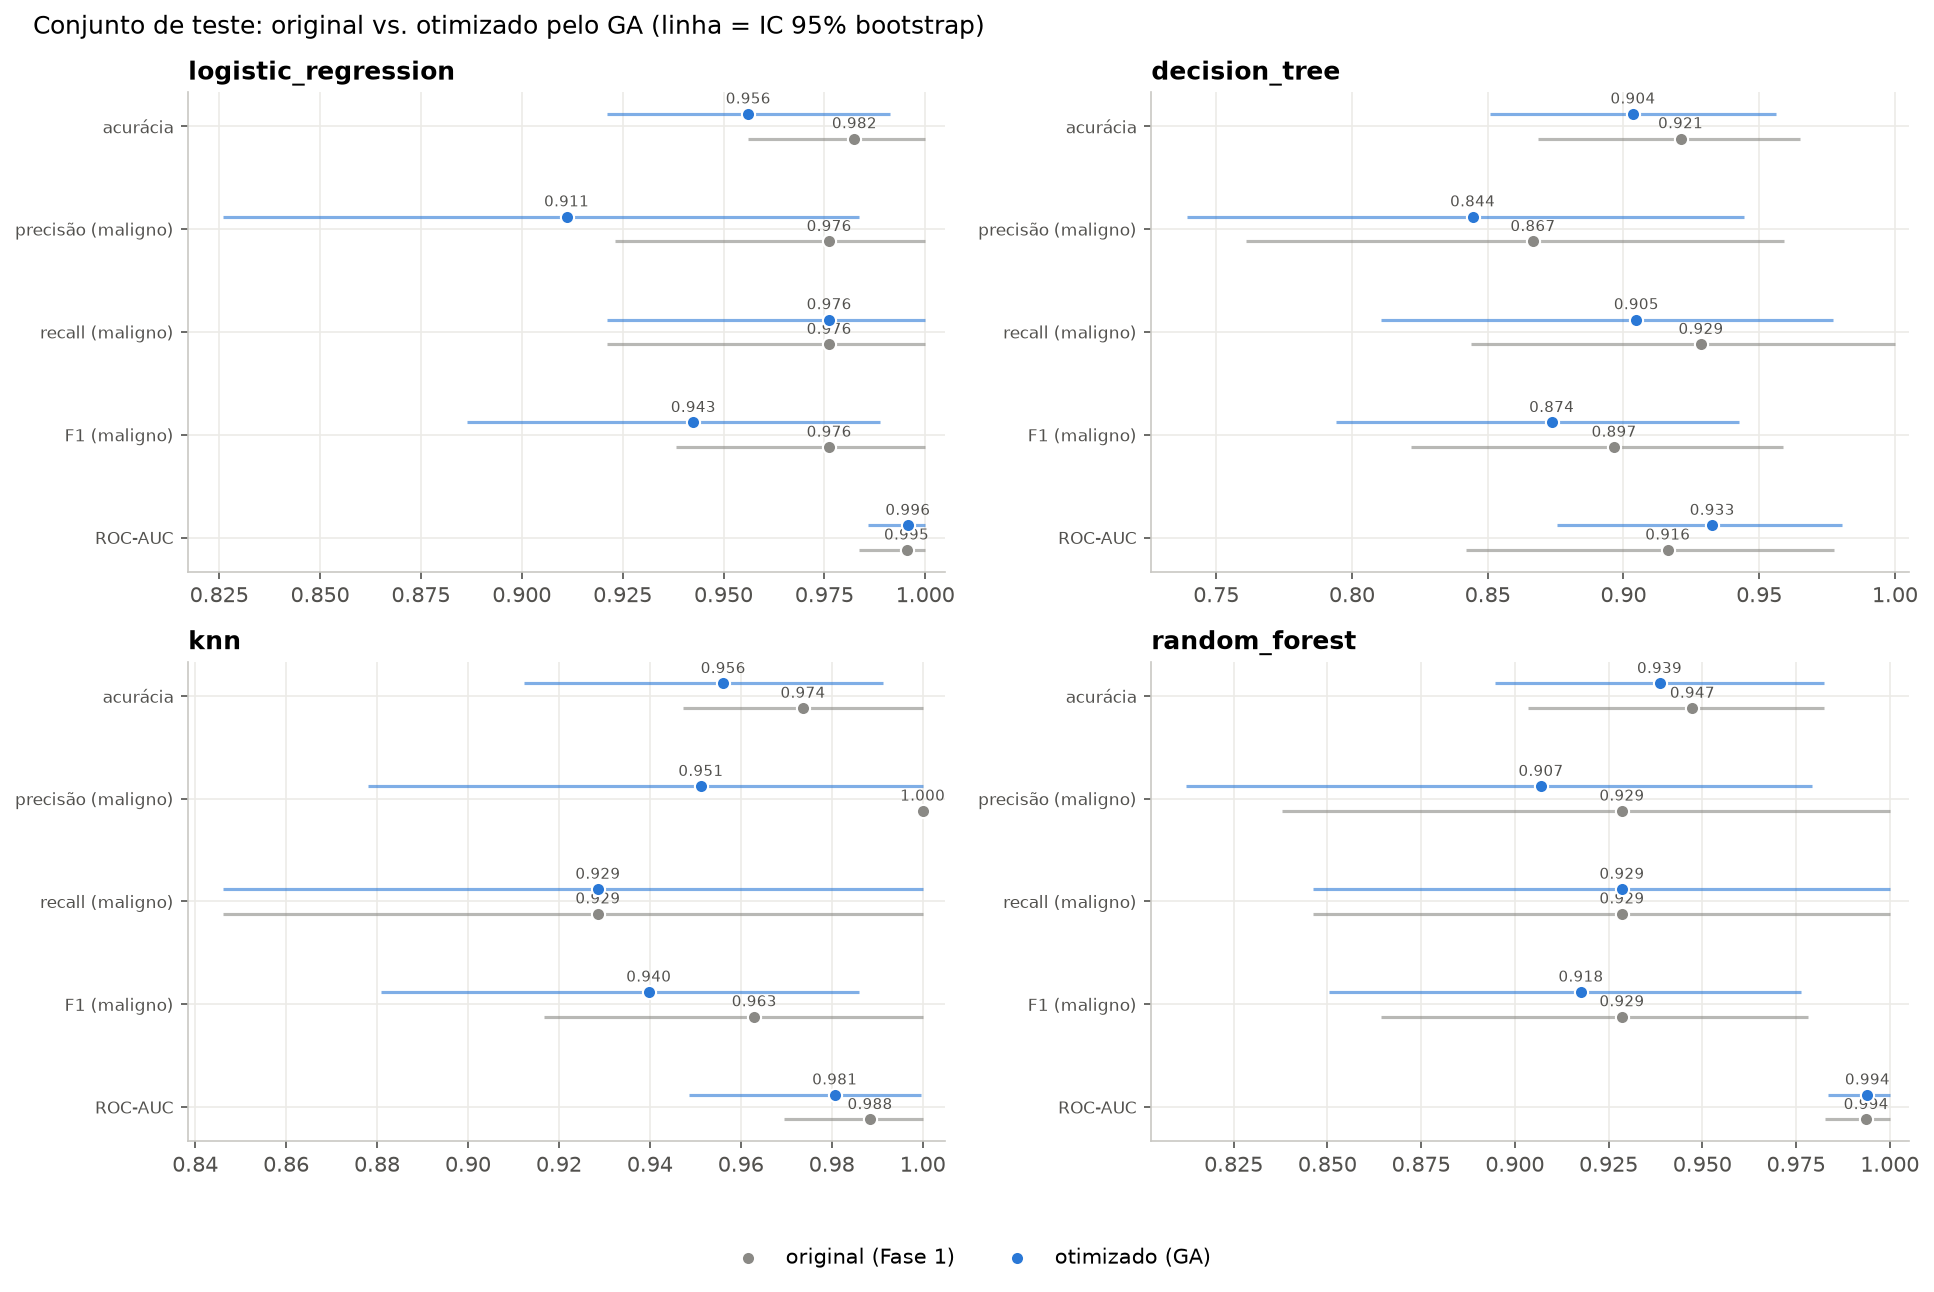

In [10]:
display(Image(FIGS / "ga_04_original_vs_optimized.png"))

In [11]:
best = json.loads((REPORTS / "ga_best_params.json").read_text(encoding="utf-8"))
pd.DataFrame({m: {"experimento": b["experiment"], "fitness CV": round(b["cv_fitness"], 4),
                  "fitness CV original": round(b["baseline_cv_fitness"], 4),
                  "hiperparâmetros": b["params"]} for m, b in best.items()}).T

,experimento,fitness CV,fitness CV original,hiperparâmetros
logistic_regression,E2_populacao_grande,0.9768,0.9666,"{'C': 0.3820136957594292, 'l1_ratio': 0.175790..."
decision_tree,E2_populacao_grande,0.9397,0.8948,"{'max_depth': 8, 'min_samples_split': 9, 'min_..."
knn,E1_referencia,0.963,0.9551,"{'n_neighbors': 4, 'weights': 'uniform', 'p': 1}"
random_forest,E3_mutacao_alta,0.9653,0.9531,"{'n_estimators': 343, 'max_depth': 6, 'min_sam..."


### 3.1 Comparação robusta: validação cruzada aninhada

O teste tem só 114 pacientes. Na validação aninhada o GA roda dentro de cada fold externo (5 folds × 2
repetições) e original e otimizado são comparados, pareados, em pacientes que o GA nunca viu.

In [12]:
nested = pd.read_csv(REPORTS / "nested_cv_summary.csv")
nested[["model", "metric", "original_mean", "otimizado_mean", "diff_mean", "wins", "ties", "losses", "wilcoxon_p"]].round(4)

,model,metric,original_mean,otimizado_mean,diff_mean,wins,ties,losses,wilcoxon_p
0,logistic_regression,test_accuracy,0.9745,0.9727,-0.0018,3,4,3,0.8750
1,logistic_regression,test_precision_malignant,0.9812,0.9701,-0.0111,1,5,4,0.1250
2,logistic_regression,test_recall_malignant,0.9504,0.9574,0.0070,5,3,2,0.6250
3,logistic_regression,test_f1_malignant,0.9649,0.9631,-0.0018,5,2,3,0.9453
4,logistic_regression,test_roc_auc,0.9947,0.9944,-0.0003,5,0,5,0.8262
5,decision_tree,test_accuracy,0.9350,0.9315,-0.0035,6,0,4,0.9043
6,decision_tree,test_precision_malignant,0.9144,0.9011,-0.0133,5,0,5,0.8457
7,decision_tree,test_recall_malignant,0.9125,0.9268,0.0143,5,0,5,0.3066
8,decision_tree,test_f1_malignant,0.9117,0.9108,-0.0010,6,0,4,0.7695
9,decision_tree,test_roc_auc,0.9242,0.9625,0.0383,9,1,0,0.0039


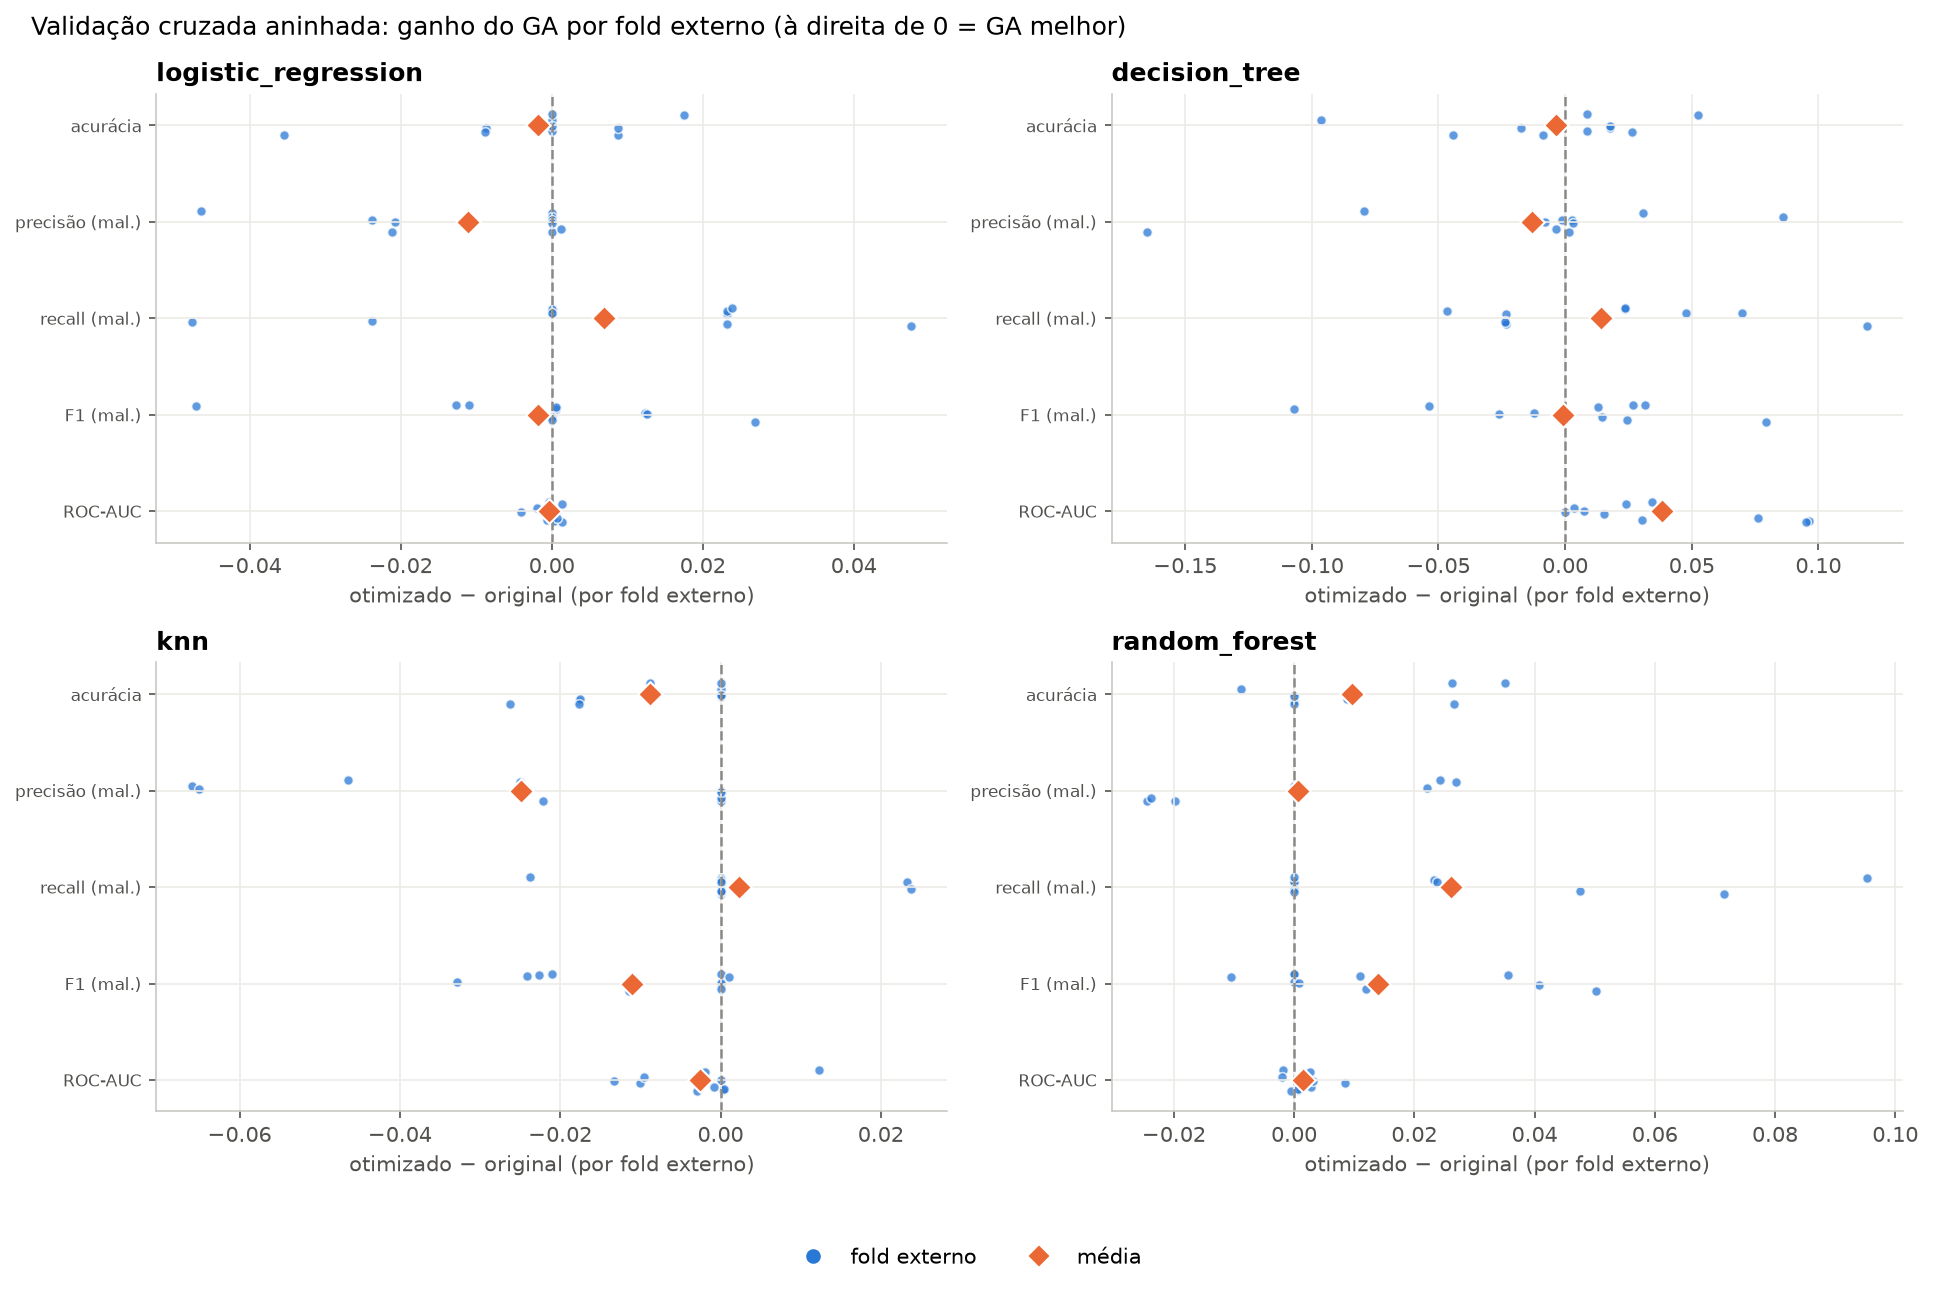

In [13]:
display(Image(FIGS / "ga_07_nested_cv_paired.png"))

## 4. Extra — GA na CNN (ResNet18, transfer learning, GPU)

,model,version,test_accuracy,test_precision_malignant,test_recall_malignant,test_f1_malignant,test_roc_auc,epochs_trained
0,cnn_resnet18_transfer,original,0.6591,0.5629,0.5833,0.5730,0.7186,10
1,cnn_resnet18_transfer,otimizado_ga,0.6974,0.6145,0.6123,0.6134,0.7438,13


{'lr': 0.0004904831803531279,
 'weight_decay': 0.0001,
 'dropout': 0.3838349727551688,
 'unfreeze_from': 'layer3',
 'batch_size': 32,
 'pos_weight_scale': 1.497276284888048}

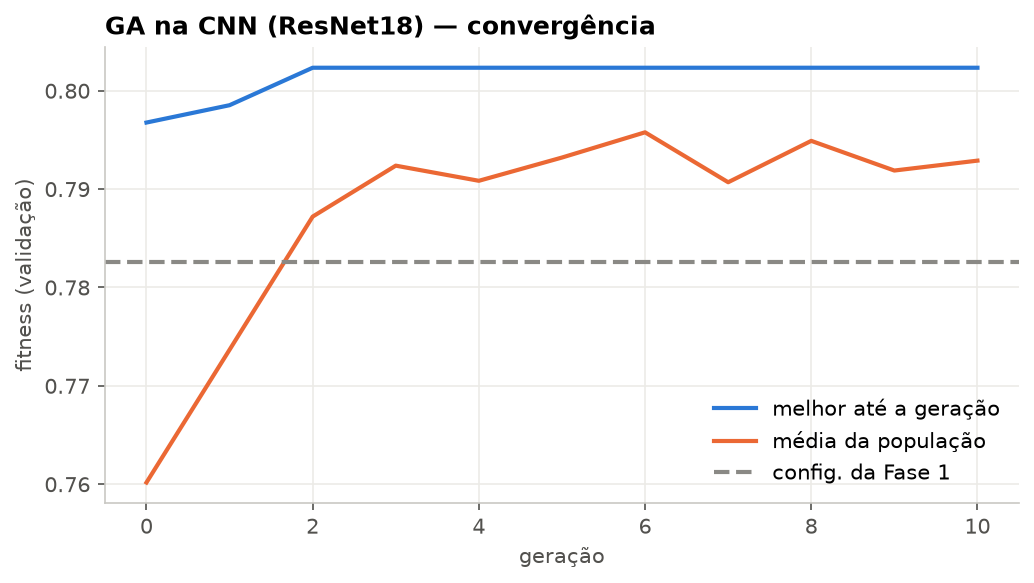

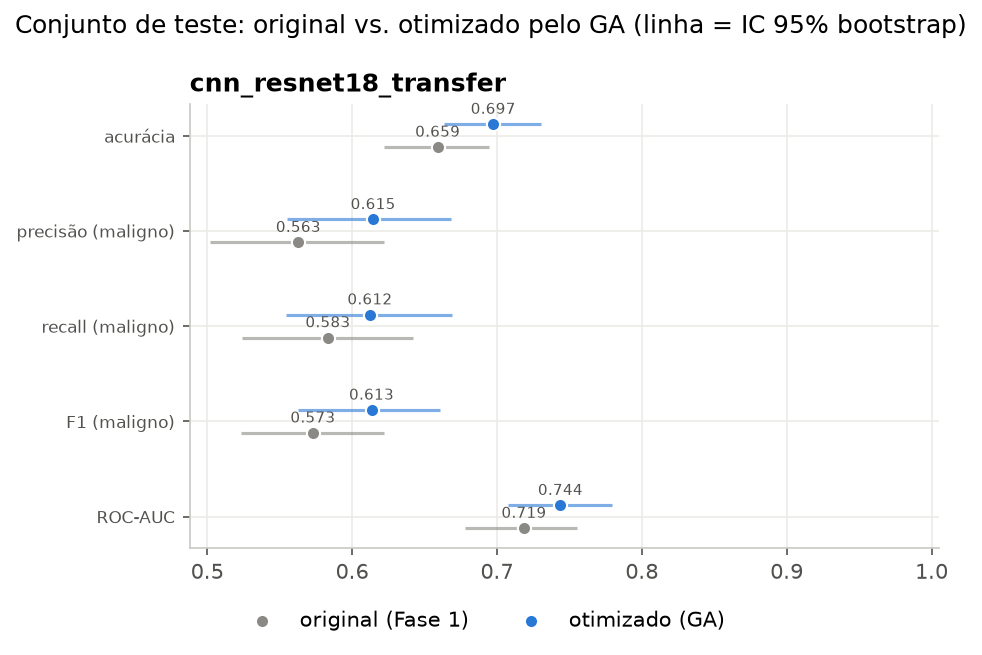

In [14]:
cnn_path = REPORTS / "cnn_comparison_original_vs_optimized.csv"
if cnn_path.exists():
    cnn = pd.read_csv(cnn_path)
    display(cnn[[c for c in cnn.columns if "_ci_" not in c]].round(4))
    display(json.loads((REPORTS / "cnn_ga_best_params.json").read_text(encoding="utf-8"))["best_params"])
    display(Image(FIGS / "cnn_ga_02_convergence.png"))
    display(Image(FIGS / "cnn_ga_01_original_vs_optimized.png"))
else:
    print("Rode `python main_ga_cnn.py` para gerar os resultados da CNN.")

## 5. LLM — do número ao insight

O **contexto do caso** é tudo que a LLM recebe: predição, probabilidade, confiança, os 5 fatores
SHAP mais influentes (em pontos de probabilidade) e onde cada valor do paciente se situa em relação
aos casos benignos e malignos.

In [15]:
from src import serving
model = serving.load_production_model()
builder = serving.load_context_builder(model.name)
contexts = builder.build(split.X_test, patient_ids=[f"T{i:03d}" for i in split.X_test.index], y_true=split.y_test)
ctx = next(c for c in contexts if c.confidence != "alta")   # um caso limítrofe
print("Modelo de produção:", model.name)
print(json.dumps(ctx.to_prompt_dict(), ensure_ascii=False, indent=2))

Modelo de produção: logistic_regression
{
  "patient_id": "T363",
  "model_name": "logistic_regression",
  "predicted_label": "maligno",
  "prob_malignant": 0.57,
  "confidence": "baixa",
  "base_rate_malignant": 0.415,
  "top_factors": [
    {
      "feature": "worst symmetry",
      "feature_pt": "simetria do núcleo — pior valor",
      "value": 0.2394,
      "contribution": -0.057,
      "effect": "reduz_risco",
      "percentile": 18,
      "median_benign": 0.2678,
      "median_malignant": 0.3149,
      "closer_to": "benignos"
    },
    {
      "feature": "worst radius",
      "feature_pt": "raio do núcleo celular — pior valor",
      "value": 18.13,
      "contribution": 0.048,
      "effect": "aumenta_risco",
      "percentile": 74,
      "median_benign": 13.34,
      "median_malignant": 20.41,
      "closer_to": "malignos"
    },
    {
      "feature": "mean radius",
      "feature_pt": "raio do núcleo celular — média",
      "value": 16.5,
      "contribution": 0.041,
      "

In [16]:
from src.llm.client import OllamaClient
from src.llm.explainer import DiagnosisExplainer
from src.llm.quality import evaluate_explanation

llm = OllamaClient(model="qwen2.5:7b")
if llm.is_available():
    exp = DiagnosisExplainer(llm, "v4_calculos_no_codigo").explain(ctx)
    display(Markdown(exp.text))
    q = evaluate_explanation(ctx, exp.text, exp.structured)
    print({k: q[k] for k in ("auto_score", "grounding_rate", "factor_coverage", "direction_accuracy", "has_disclaimer", "flesch_pt")})
    print(f"latência: {exp.latency_seconds:.1f}s")
else:
    print("Ollama indisponível — exibindo uma explicação salva por main_llm.py")
    rec = [json.loads(l) for l in open(REPORTS / "llm_explanations.jsonl", encoding="utf-8")]
    display(Markdown(next(r for r in rec if r["explanation"]["prompt_version"] == "v4_calculos_no_codigo")["explanation"]["text"]))

**Classificação do modelo:** maligno (probabilidade de malignidade 57%, confiança baixa)

O modelo classificou a lesão como maligna, com probabilidade de 57% (confiança baixa). O resultado é puxado principalmente pela simetria do núcleo e pelo raio do núcleo celular, parcialmente compensados por outros fatores morfológicos. Trata-se de um caso limítrofe.

**Fatores principais**
- Simetria do núcleo — pior valor = 0.2394 (↓ risco): Percentil 18; abaixo da mediana dos benignos (0.2678) e próxima da mediana dos malignos (0.3149). Foi o fator de maior peso: -5.7 pontos na probabilidade.
- Raio do núcleo celular — pior valor = 18.13 (↑ risco): Percentil 74; entre as medianas de benignos (13.34) e malignos (20.41), mais próxima dos malignos. Contribuiu com +4.8 pontos.
- Raio do núcleo celular — média = 16.5 (↑ risco): Percentil 79; entre as medianas de benignos (12.18) e malignos (17.2), mais próxima dos malignos. Contribuiu com +4.1 pontos.
- Perímetro do núcleo — pior valor = 117.2 (↑ risco): Percentil 71; entre as medianas de benignos (86.67) e malignos (135.1), mais próxima dos malignos. Contribuiu com +3.5 pontos.
- Perímetro do núcleo — média = 106.6 (↑ risco): Percentil 77; entre as medianas de benignos (78.07) e malignos (113.2), mais próxima dos malignos. Contribuiu com +3.5 pontos.

**Sugestões de investigação**
- Correlacionar com achados de imagem (mamografia/ultrassonografia e classificação BI-RADS).
- Por ser caso limítrofe, considerar biópsia por agulha grossa para confirmação histopatológica.
- Revisar a lâmina com atenção à simetria do contorno nuclear, principal fator do modelo.

**Limitações**
- Confiança baixa: a probabilidade está a 7 pontos do limiar de decisão (50%).
- O modelo considera apenas morfologia nuclear; não inclui idade, histórico ou exames de imagem.

_Ferramenta de apoio à decisão. Não substitui a avaliação médica nem o exame histopatológico._

{'auto_score': 1.0, 'grounding_rate': 1.0, 'factor_coverage': 1.0, 'direction_accuracy': 1.0, 'has_disclaimer': True, 'flesch_pt': 50.79804587802397}
latência: 9.9s


### Perguntas em linguagem natural

In [17]:
qa = json.loads((REPORTS / "llm_qa.json").read_text(encoding="utf-8"))
for item in qa:
    display(Markdown(f"**Pergunta:** {item['question']}\n\n**Resposta ({item['llm']}):** {item['answer']}"))

**Pergunta:** Qual característica mais pesou para essa classificação e por quê?

**Resposta (qwen2.5:7b):** A característica que mais pesou para essa classificação foi a "simetria do núcleo — pior valor", com uma contribuição de -5,7 pontos percentuais. Isso significa que um valor mais alto nesta medida reduziu a probabilidade de malignidade, empurrando a classificação para o lado benigno.

**Pergunta:** O quanto posso confiar nesse resultado?

**Resposta (qwen2.5:7b):** O resultado tem uma confiança moderada, indicando que o caso é limítrofe e merece atenção redobrada.

**Pergunta:** Quais exames complementares fariam sentido antes de decidir a conduta?

**Resposta (qwen2.5:7b):** O fator que mais pesou na classificação foi a simetria do núcleo — pior valor, com um impacto de -5,7 pontos percentuais. Embora a probabilidade de malignidade seja baixa (21,6%), o caso é moderadamente confiante e merece atenção redobrada. Sugiro considerar uma biópsia de core para confirmar a natureza da lesão, especialmente se a simetria continuar sendo um valor atípico. Correlacione os resultados com imagens de ressonância magnética ou mamografia para avaliar a consistência da lesão.

**Pergunta:** Qual o tratamento indicado para essa paciente?

**Resposta (qwen2.5:7b):** Os dados fornecidos não são suficientes para indicar um tratamento específico. A classificação do modelo como benigno com probabilidade de 21,6% sugere que a lesão é mais provavelmente benigna, mas a confiança é moderada, indicando que o caso é limítrofe. Recomenda-se realizar uma biópsia de core para confirmação e considerar a avaliação por um mastologista para orientações sobre o manejo clínico.

## 6. Avaliação da qualidade das interpretações

In [18]:
qs = pd.read_csv(REPORTS / "llm_quality_summary.csv")
cols = [c for c in ["llm", "prompt_version", "auto_score", "label_consistent", "prob_consistent", "grounding_rate",
                    "factor_coverage", "direction_accuracy", "has_disclaimer", "flags_uncertainty", "flesch_pt",
                    "latency_s", "judge_fidelidade", "judge_clareza", "judge_utilidade_clinica", "judge_seguranca",
                    "judge_mean"] if c in qs.columns]
qs[cols].round(3)

,llm,prompt_version,auto_score,label_consistent,prob_consistent,grounding_rate,factor_coverage,direction_accuracy,has_disclaimer,flesch_pt,latency_s,judge_fidelidade,judge_clareza,judge_utilidade_clinica,judge_seguranca,judge_mean
0,llama3.1:8b,v1_zero_shot,0.731,1.0,1.0,1.000,0.975,NaN,0.0,69.451,15.475,4.5,3.875,3.75,4.5,4.156
1,llama3.1:8b,v2_estruturado,0.873,1.0,1.0,0.979,1.000,1.0,0.5,59.653,12.620,5.0,5.000,5.00,5.0,5.000
2,llama3.1:8b,v3_few_shot,0.971,1.0,1.0,0.991,1.000,1.0,1.0,48.582,13.570,5.0,5.000,5.00,5.0,5.000
3,llama3.1:8b,v4_calculos_no_codigo,0.972,1.0,1.0,1.000,1.000,1.0,1.0,50.052,13.190,5.0,5.000,5.00,5.0,5.000
4,qwen2.5:7b,v1_zero_shot,0.828,1.0,1.0,1.000,1.000,NaN,0.5,54.732,13.928,5.0,5.000,5.00,5.0,5.000
5,qwen2.5:7b,v2_estruturado,0.984,1.0,1.0,0.983,1.000,1.0,1.0,45.123,13.012,5.0,5.000,5.00,5.0,5.000
6,qwen2.5:7b,v3_few_shot,0.986,1.0,1.0,0.996,1.000,1.0,1.0,45.413,12.546,5.0,5.000,5.00,5.0,5.000
7,qwen2.5:7b,v4_calculos_no_codigo,0.986,1.0,1.0,1.000,1.000,1.0,1.0,47.836,12.444,5.0,5.000,5.00,5.0,5.000


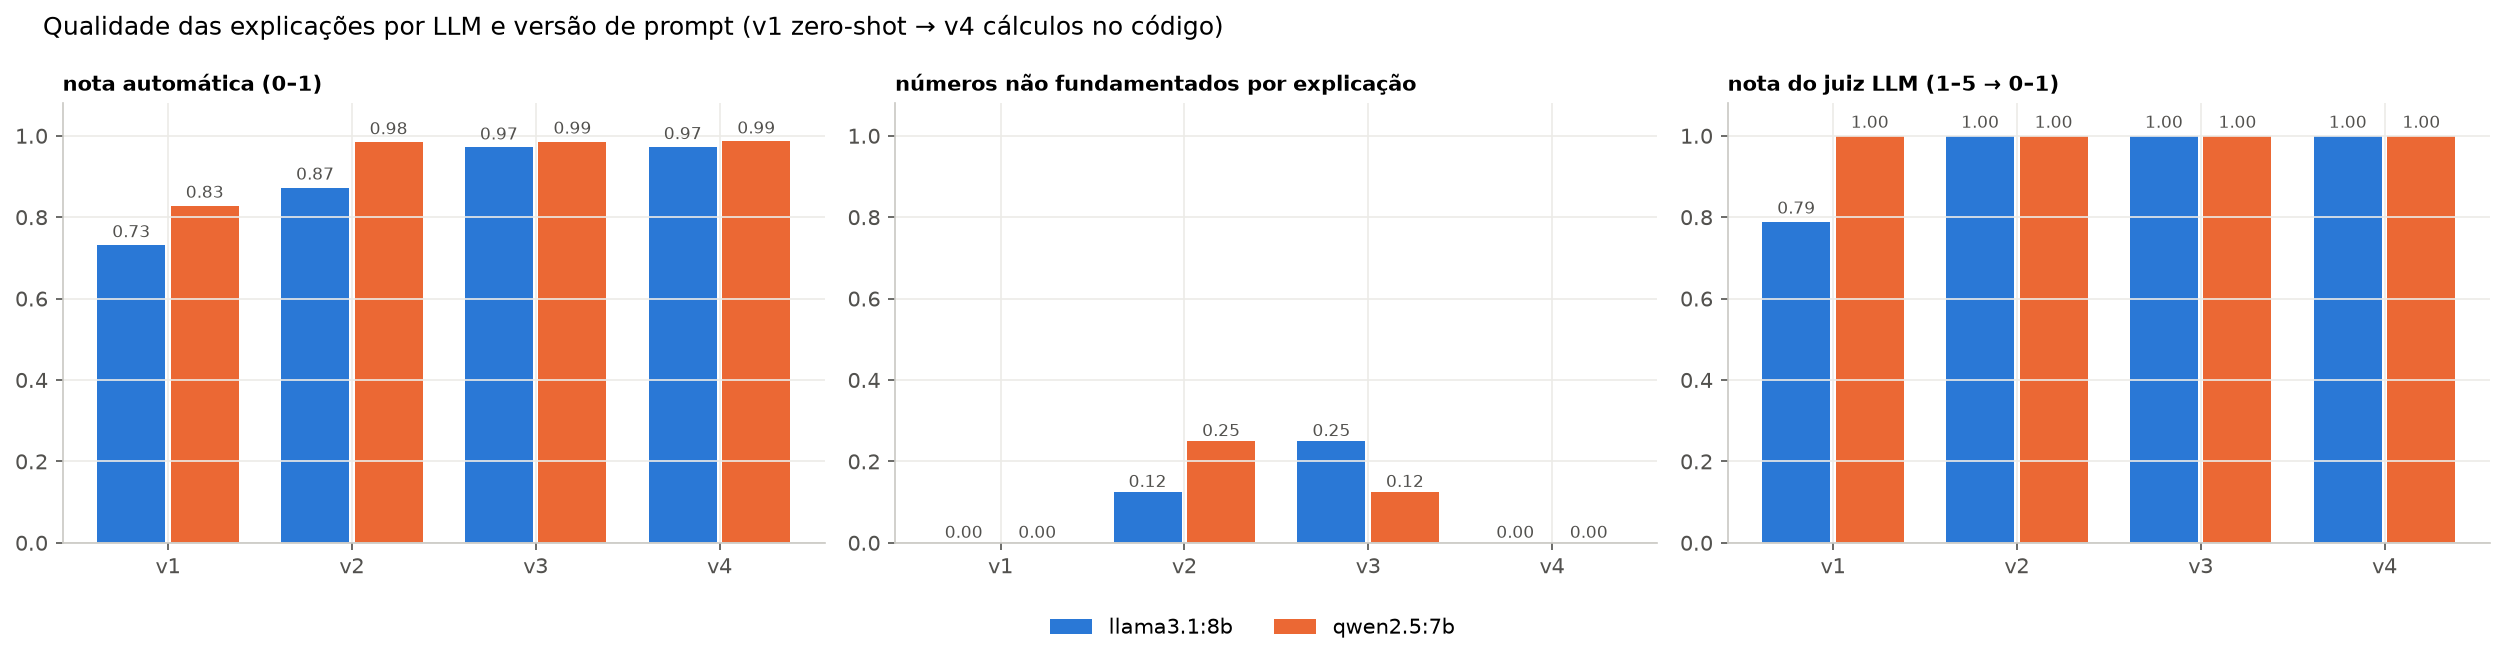

In [19]:
display(Image(FIGS / "llm_01_quality.png"))

### Escalabilidade automática (Kubernetes HPA, teste local com kind)

,estagio,concorrencia,duracao_s,req_s,erros,p50_ms,p95_ms
0,inicio,4,30,227.5,0,16,29
1,pico,32,240,502.3,0,61,109
2,fim_10_replicas,4,30,699.6,0,5,9


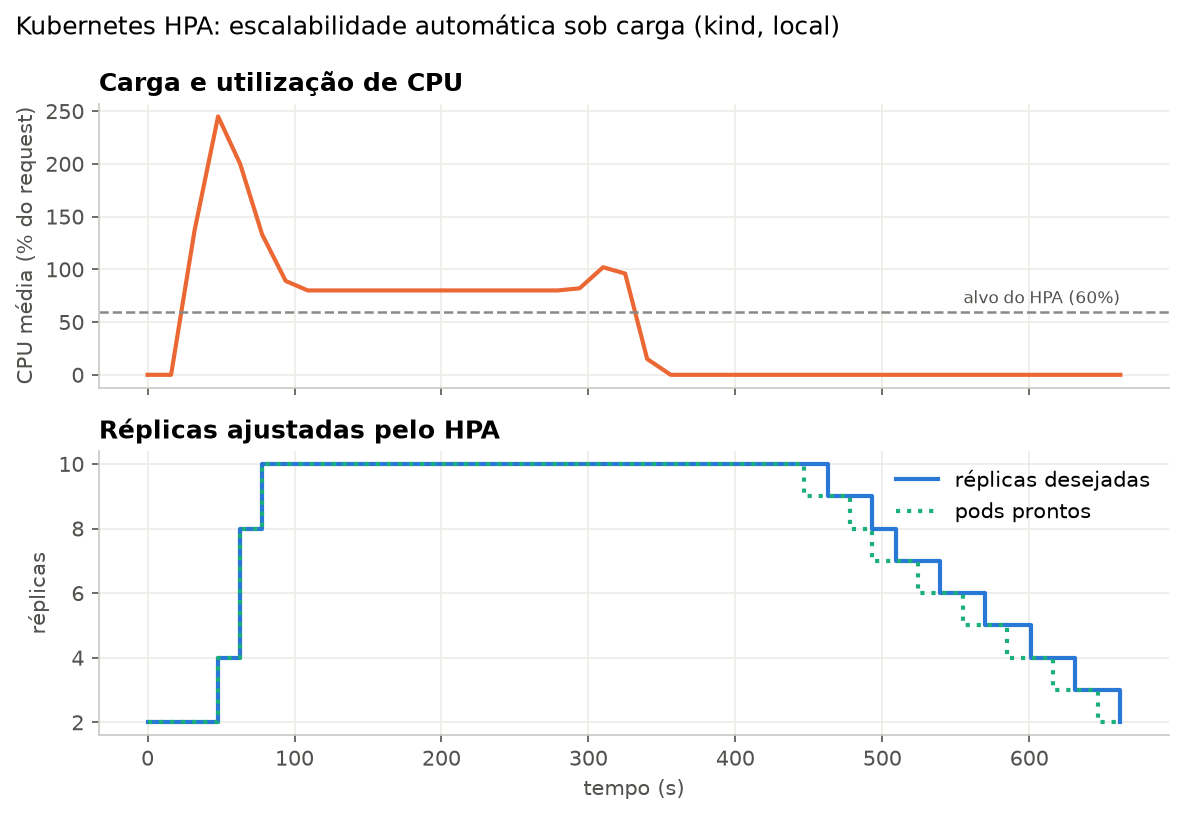

In [20]:
display(pd.read_csv(REPORTS / "k8s_load_test.csv"))
display(Image(FIGS / "infra_01_hpa_scaling.png"))

## 7. API

Com a API rodando (`uvicorn src.api.app:app` ou `docker compose up`), o mesmo fluxo é exposto via HTTP:

In [21]:
import requests
try:
    patient = requests.get("http://localhost:8000/examples", params={"n": 1}, timeout=3).json()[0]
    pred = requests.post("http://localhost:8000/predict", json={"patients": [patient]}, timeout=10).json()
    print(pred)
except requests.RequestException:
    print("API não está rodando — veja o README (seção 4).")

API não está rodando — veja o README (seção 4).
